# 03 · Жильё, школы и районы

Ноутбук воспроизводит часть данных этапа 02 и `03_district_spatial_join` у любого участника. Источники зафиксированы, файлы Давида не нужны:
- **жильё и школы** — из зафиксированного снимка OSM `kazakhstan-261118`, через вырезку `data/raw/almaty_osm_extract.gpkg` из `03_osm_commercial_features.ipynb`;
- **границы районов** — тот же публичный слой ArcGIS, что в `03_district_spatial_join.ipynb`. Ответ сохраняется в `data/raw/` и при следующих запусках берётся оттуда.

Правила подсчёта те же, что в 02:
- жилые здания — `building` = house, detached, apartments, residential. Каждое здание заменяется точкой внутри него и считается в радиусе 500 м. house + detached дают частные дома, apartments — многоквартирные, residential — жильё без подтипа;
- школы — `amenity=school`, полигоны и точки. Одна школа может быть и точкой, и полигоном, и вложенным полигоном, поэтому считаются уникальные школы, геометрия которых попадает в 500 м.

В 02 склейка школ задана вручную номерами строк. Здесь те же решения записаны правилами, и они работают на любом снимке:
1. полигон внутри другого школьного полигона — та же школа, что и внешний;
2. точка внутри полигона — та же школа;
3. если в полигоне две и больше точек с разными названиями, это общий двор нескольких школ: точки — отдельные школы, а полигон не считается.

Признаки получают префикс `osm_`. Так они не совпадают по имени с признаками 02, и в мастер-датасете их можно сравнить.

**Выходы**
- `data/processed/features/osm_residential_schools.csv` — `candidate_id, x, y` и 5 признаков;
- `data/processed/almaty_districts.parquet` — границы 8 районов;
- `data/processed/qa/schools_groups.csv` — каждая школьная геометрия: её `school_id` и правило склейки.

In [1]:
import hashlib
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import requests
import shapely

PROJECT_ROOT = (Path("..") if Path.cwd().name == "notebooks" else Path(".")).resolve()
EXTRACT_PATH = PROJECT_ROOT / "data" / "raw" / "almaty_osm_extract.gpkg"
BOUNDARY_PATH = PROJECT_ROOT / "data" / "processed" / "almaty_boundary.gpkg"
CANDIDATES_PATH = PROJECT_ROOT / "data" / "processed" / "candidate_locations.gpkg"
DISTRICTS_URL = ("https://services.arcgis.com/HOo89W8RWwrXP286/arcgis/rest/services/Almaty_Districts/FeatureServer/0/query"
                 "?where=1%3D1&outFields=%2A&returnGeometry=true&outSR=4326&f=geojson")
DISTRICTS_RAW = PROJECT_ROOT / "data" / "raw" / "almaty_districts_arcgis.geojson"
DISTRICTS_OUT = PROJECT_ROOT / "data" / "processed" / "almaty_districts.parquet"
FEATURES_OUT = PROJECT_ROOT / "data" / "processed" / "features" / "osm_residential_schools.csv"
QA_SCHOOLS = PROJECT_ROOT / "data" / "processed" / "qa" / "schools_groups.csv"

CRS_METRIC = "EPSG:32643"
N_CANDIDATES = 2822
RADIUS_M = 500
RESIDENTIAL_GROUPS = {"house": "houses", "detached": "houses", "apartments": "apartments", "residential": "residential_unknown"}

for path in (EXTRACT_PATH, BOUNDARY_PATH, CANDIDATES_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Нет {path.relative_to(PROJECT_ROOT)}: сначала 02 и 03_osm_commercial_features.")
meta = dict(pyogrio.read_dataframe(EXTRACT_PATH, layer="extract_meta", read_geometry=False)[["key", "value"]].values)
print("Вырезка OSM:", meta.get("pbf_name"), "md5", meta.get("pbf_md5"))

city = gpd.read_file(BOUNDARY_PATH).to_crs(CRS_METRIC)
city_geometry = shapely.union_all(city.geometry.to_numpy())
candidates = gpd.read_file(CANDIDATES_PATH)[["candidate_id", "geometry"]].to_crs(CRS_METRIC)
assert len(candidates) == N_CANDIDATES and candidates["candidate_id"].is_unique

Вырезка OSM: kazakhstan-261118.osm.pbf md5 57fd297ad55df539e0ec233312922ca0


## Функции

`count_within` — число точек в радиусе от каждого кандидата. `group_schools` склеивает школьные геометрии по трём правилам выше. Для каждой геометрии он возвращает `school_id` и название правила.

In [2]:
def count_within(candidates, geoms, radius_m):
    """Число геометрий не дальше radius_m от каждого кандидата (для полигона — от ближайшей его точки)."""
    if len(geoms) == 0:
        return np.zeros(len(candidates), dtype=int)
    cand_pos, _ = geoms.sindex.query(candidates.geometry, predicate="dwithin", distance=radius_m)
    return np.bincount(cand_pos, minlength=len(candidates))


def count_unique_within(candidates, geoms, id_col, radius_m):
    """Число уникальных id среди геометрий в радиусе (одна школа = одна, сколько бы у неё ни было геометрий)."""
    cand_pos, geom_pos = geoms.sindex.query(candidates.geometry, predicate="dwithin", distance=radius_m)
    pairs = pd.DataFrame({"c": cand_pos, "id": geoms[id_col].to_numpy()[geom_pos]}).drop_duplicates()
    return np.bincount(pairs["c"].to_numpy(), minlength=len(candidates))


def _norm_name(value):
    return value.strip().lower() if isinstance(value, str) and value.strip() else None


def group_schools(polys, points):
    """school_id для полигонов и точек amenity=school. Вход в метрической CRS, со столбцами osm_ref и name."""
    polys = polys.reset_index(drop=True).copy()
    points = points.reset_index(drop=True).copy()
    polys["school_id"] = "polygon:" + polys["osm_ref"]
    polys["rule"] = "своя территория"
    # 1. вложенный полигон → самый крупный из содержащих его школьных полигонов
    inner, outer = polys.sindex.query(polys.geometry, predicate="within")
    keep = inner != outer
    if keep.any():
        nest = pd.DataFrame({"inner": inner[keep], "outer": outer[keep]})
        nest["outer_area"] = polys.geometry.area.to_numpy()[nest["outer"]]
        nest = nest.sort_values(["inner", "outer_area"], ascending=[True, False]).drop_duplicates("inner")
        for row in nest.itertuples():
            polys.loc[row.inner, "school_id"] = polys.loc[row.outer, "school_id"]
            polys.loc[row.inner, "rule"] = "вложен в полигон " + polys.loc[row.outer, "osm_ref"]
    # 2–3. точки внутри полигонов
    points["school_id"] = "point:" + points["osm_ref"]
    points["rule"] = "отдельная точка"
    pt, pg = polys.sindex.query(points.geometry, predicate="within")
    hits = pd.DataFrame({"point": pt, "polygon": pg})
    hits["group"] = polys["school_id"].to_numpy()[hits["polygon"]]
    hits = hits.drop_duplicates("point")  # точка внутри вложенных полигонов — одна группа
    names = points["name"].map(_norm_name)
    drop_groups = set()
    for group, part in hits.groupby("group"):
        distinct = {names[p] for p in part["point"] if names[p] is not None}
        if len(distinct) >= 2:  # общий двор нескольких школ: точки — отдельные школы, полигон не считаем
            drop_groups.add(group)
            for p in part["point"]:
                points.loc[p, "rule"] = "отдельная школа в общем полигоне " + group
        else:
            for p in part["point"]:
                points.loc[p, "school_id"] = group
                points.loc[p, "rule"] = "точка внутри полигона " + group
    polys.loc[polys["school_id"].isin(drop_groups), "rule"] = "общий полигон нескольких школ — не считается"
    counted = polys[~polys["school_id"].isin(drop_groups)]
    schools = pd.concat([counted.assign(source_type="polygon"), points.assign(source_type="point")], ignore_index=True)
    qa = pd.concat([polys.assign(source_type="polygon"), points.assign(source_type="point")], ignore_index=True)
    return gpd.GeoDataFrame(schools, geometry="geometry", crs=polys.crs), pd.DataFrame(qa.drop(columns="geometry"))

## Офлайн-тесты

In [3]:
import unittest


class ContextTests(unittest.TestCase):
    def test_count_within(self):
        cands = gpd.GeoDataFrame(geometry=gpd.points_from_xy([0, 1000], [0, 0]), crs=CRS_METRIC)
        pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy([100, 500, 900, 5000], [0, 0, 0, 0]), crs=CRS_METRIC)
        self.assertEqual(count_within(cands, pts, 500).tolist(), [2, 2])
        self.assertEqual(count_within(cands, pts.iloc[:0], 500).tolist(), [0, 0])

    def test_school_rules(self):
        box = shapely.box
        polys = gpd.GeoDataFrame({"osm_ref": ["way/1", "way/2", "way/3", "way/4"], "name": ["Гимназия 15", None, "Двор", "Школа 9"]},
                                 geometry=[box(0, 0, 200, 200), box(50, 50, 100, 100),      # 2 вложен в 1
                                           box(1000, 0, 1200, 200),                          # общий двор
                                           box(3000, 0, 3100, 100)], crs=CRS_METRIC)         # своя территория
        points = gpd.GeoDataFrame({"osm_ref": ["node/1", "node/2", "node/3", "node/4", "node/5"],
                                   "name": ["Гимназия 15", "Лицей 134", "Школа 135", None, "Школа 7"]},
                                  geometry=gpd.points_from_xy([60, 1050, 1150, 3050, 5000], [60, 50, 50, 50, 0]), crs=CRS_METRIC)
        schools, qa = group_schools(polys, points)
        ids = dict(zip(qa["osm_ref"], qa["school_id"]))
        self.assertEqual(ids["way/2"], "polygon:way/1")
        self.assertEqual(ids["node/1"], "polygon:way/1")
        self.assertEqual(ids["node/2"], "point:node/2")
        self.assertEqual(ids["node/3"], "point:node/3")
        self.assertEqual(ids["node/4"], "polygon:way/4")
        self.assertEqual(ids["node/5"], "point:node/5")
        self.assertNotIn("way/3", set(schools["osm_ref"]))  # общий двор не считается
        self.assertEqual(schools["school_id"].nunique(), 5)  # гимназия 15, лицей 134, школа 135, школа 9, школа 7
        cands = gpd.GeoDataFrame(geometry=gpd.points_from_xy([100, 1100], [100, 100]), crs=CRS_METRIC)
        self.assertEqual(count_unique_within(cands, schools, "school_id", 300).tolist(), [1, 2])


suite = unittest.defaultTestLoader.loadTestsFromTestCase(ContextTests)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
if not test_result.wasSuccessful():
    raise AssertionError("Проверки ноутбука завершились ошибкой.")

test_count_within (__main__.ContextTests.test_count_within) ... 

ok


test_school_rules (__main__.ContextTests.test_school_rules) ... 

ok


----------------------------------------------------------------------
Ran 2 tests in 0.036s

OK


## Районы

Слой районов скачивается один раз и сохраняется как есть в `data/raw/almaty_districts_arcgis.geojson`. Повторный запуск читает этот файл: так у всех одни и те же границы. Чтобы скачать свежую версию, удалите файл.

In [4]:
if not DISTRICTS_RAW.is_file():
    response = requests.get(DISTRICTS_URL, timeout=60)
    response.raise_for_status()
    payload = response.json()
    if payload.get("type") != "FeatureCollection" or len(payload.get("features", [])) != 8:
        raise ValueError("ArcGIS вернул не 8 районов — проверьте слой вручную.")
    DISTRICTS_RAW.write_bytes(response.content)
print("Снимок границ районов:", DISTRICTS_RAW.relative_to(PROJECT_ROOT),
      "sha256", hashlib.sha256(DISTRICTS_RAW.read_bytes()).hexdigest()[:16], "…")
districts = gpd.read_file(DISTRICTS_RAW)
districts["NAME"] = districts["NAME"].str.strip()
assert len(districts) == 8 and districts["NAME"].is_unique and districts.geometry.is_valid.all()
assert districts.crs.to_epsg() == 4326
districts.to_parquet(DISTRICTS_OUT)
inside = shapely.covers(shapely.union_all(districts.to_crs(CRS_METRIC).geometry.to_numpy()), candidates.geometry.to_numpy())
print(f"Сохранено: {DISTRICTS_OUT.relative_to(PROJECT_ROOT)}; кандидатов внутри полигонов районов: {inside.sum()} из {len(candidates)}")
display(pd.DataFrame(districts.drop(columns="geometry")))

Снимок границ районов: data\raw\almaty_districts_arcgis.geojson sha256 164664be6200c561 …


Сохранено: data\processed\almaty_districts.parquet; кандидатов внутри полигонов районов: 2808 из 2822


,OBJECTID,NAME,RAION,GlobalID,Population_est,Schools_capacity,Students_to_population,Shape__Area,Shape__Length
0,1,Ауэзовский,312,db4a4813-efd1-471d-893b-3f2507c46d0e,216162,53708,248,2.954654e+07,25014.992782
1,2,Алатауский,321,78d6ecb8-2019-4749-97b2-804f490cbe32,182493,51706,283,1.307575e+08,72807.531267
2,3,Медеуский,315,4961c1d5-0d34-47fc-9771-73b2da36b5a5,172300,30419,177,3.421883e+08,160289.173415
3,4,Наурызбайский,322,802307fb-e1a6-427d-8d89-48b0f92d4050,164413,19066,116,8.763143e+07,58380.265837
4,5,Жетысуский,314,db3f1d4c-0d4b-49ad-9830-0e2c1a20d246,114473,28551,249,4.923601e+07,51339.717717
5,6,Алмалинский,311,97219ed4-78a3-478f-8d59-5a2915064ff0,206574,34394,166,2.297755e+07,21645.651249
6,7,Турксибский,317,ba8bc05b-186a-4b01-a5b4-13fdf08c9f0b,162297,38759,239,9.435614e+07,63807.181837
7,8,Бостандыкский,313,71ed9853-facb-40b7-ba40-74b3c5cb57c8,362150,38043,105,1.219426e+08,96778.614223


## Жилая застройка

In [5]:
def osm_ref(df):
    return np.where(df["osm_id"].notna(), "relation/" + df["osm_id"].astype(str), "way/" + df["osm_way_id"].astype(str))


types = "', '".join(RESIDENTIAL_GROUPS)
residential = pyogrio.read_dataframe(EXTRACT_PATH, layer="multipolygons", where=f"building IN ('{types}')",
                                     columns=["osm_id", "osm_way_id", "building", "name"]).to_crs(CRS_METRIC)
residential["osm_ref"] = osm_ref(residential)
assert residential["osm_ref"].is_unique, "в вырезке повторяются здания"
residential["geometry"] = residential.geometry.make_valid()
residential = residential[residential.intersects(city_geometry)].copy()
residential["geometry"] = residential.geometry.representative_point()
residential["group"] = residential["building"].map(RESIDENTIAL_GROUPS)
print(f"Жилых зданий в городе: {len(residential)}", residential["building"].value_counts().to_dict())

features = pd.DataFrame({"candidate_id": candidates["candidate_id"].to_numpy(),
                         "x": candidates.geometry.x.to_numpy(), "y": candidates.geometry.y.to_numpy()})
for group in ("houses", "apartments", "residential_unknown"):
    features[f"osm_{group}_{RADIUS_M}m"] = count_within(candidates, residential[residential["group"] == group], RADIUS_M)
features[f"osm_residential_buildings_{RADIUS_M}m"] = count_within(candidates, residential, RADIUS_M)
parts = features[[f"osm_{g}_{RADIUS_M}m" for g in ("houses", "apartments", "residential_unknown")]].sum(axis=1)
assert (parts == features[f"osm_residential_buildings_{RADIUS_M}m"]).all()

Жилых зданий в городе: 63734 {'house': 55146, 'apartments': 7349, 'residential': 671, 'detached': 568}


## Школы

In [6]:
school_polys = pyogrio.read_dataframe(EXTRACT_PATH, layer="multipolygons", where="amenity = 'school'",
                                      columns=["osm_id", "osm_way_id", "name", "building"]).to_crs(CRS_METRIC)
school_polys["osm_ref"] = osm_ref(school_polys)
school_polys["geometry"] = school_polys.geometry.make_valid()
school_points = pyogrio.read_dataframe(EXTRACT_PATH, layer="points", where="other_tags LIKE '%\"amenity\"=>\"school\"%'",
                                       columns=["osm_id", "name"]).to_crs(CRS_METRIC)
school_points["osm_ref"] = "node/" + school_points["osm_id"].astype(str)
schools, schools_qa = group_schools(school_polys[["osm_ref", "name", "geometry"]], school_points[["osm_ref", "name", "geometry"]])
QA_SCHOOLS.parent.mkdir(parents=True, exist_ok=True)
schools_qa.to_csv(QA_SCHOOLS, index=False, lineterminator="\n")
print(f"Школьных геометрий: полигонов {len(school_polys)}, точек {len(school_points)}; "
      f"в счёте {len(schools)} геометрий, уникальных школ {schools['school_id'].nunique()}")
print("Правила склейки:", schools_qa["rule"].str.replace(r" (way|relation|polygon|node)\S*", "", regex=True).value_counts().to_dict())
features[f"osm_schools_{RADIUS_M}m"] = count_unique_within(candidates, schools, "school_id", RADIUS_M)

Школьных геометрий: полигонов 290, точек 39; в счёте 328 геометрий, уникальных школ 308
Правила склейки: {'своя территория': 275, 'отдельная точка': 31, 'вложен в полигон': 14, 'точка внутри полигона': 6, 'отдельная школа в общем полигоне': 2, 'общий полигон нескольких школ — не считается': 1}


## Сохранение и сравнение с 02

Справочные числа 02 взяты из выводов ноутбука Давида (его снимок OSM). Наши числа немного больше, потому что снимок свежее.

In [7]:
FEATURES_OUT.parent.mkdir(parents=True, exist_ok=True)
assert len(features) == N_CANDIDATES and features["candidate_id"].is_unique
features.to_csv(FEATURES_OUT, index=False, lineterminator="\n")
print(f"Сохранено: {FEATURES_OUT.relative_to(PROJECT_ROOT)}")

reference_02 = {  # из выводов 02_candidate_locations.ipynb
    "жилых зданий в городе": 63503, "средн. residential_buildings_500m": 69.81, "макс. residential_buildings_500m": 885,
    "кандидатов без жилья в 500 м": 1379, "уникальных школ": 297, "кандидатов со школой в 500 м": 641, "макс. schools_500m": 7,
}
ours = {
    "жилых зданий в городе": len(residential),
    "средн. residential_buildings_500m": round(features[f"osm_residential_buildings_{RADIUS_M}m"].mean(), 2),
    "макс. residential_buildings_500m": int(features[f"osm_residential_buildings_{RADIUS_M}m"].max()),
    "кандидатов без жилья в 500 м": int((features[f"osm_residential_buildings_{RADIUS_M}m"] == 0).sum()),
    "уникальных школ": int(schools["school_id"].nunique()),
    "кандидатов со школой в 500 м": int((features[f"osm_schools_{RADIUS_M}m"] > 0).sum()),
    "макс. schools_500m": int(features[f"osm_schools_{RADIUS_M}m"].max()),
}
display(pd.DataFrame({"02 (Давид)": reference_02, "этот ноутбук": ours}))
display(features.drop(columns=["candidate_id", "x", "y"]).describe().T)

Сохранено: data\processed\features\osm_residential_schools.csv


,02 (Давид),этот ноутбук
жилых зданий в городе,63503.00,63734.00
средн. residential_buildings_500m,69.81,70.19
макс. residential_buildings_500m,885.00,887.00
кандидатов без жилья в 500 м,1379.00,1356.00
уникальных школ,297.00,308.00
кандидатов со школой в 500 м,641.00,641.00
макс. schools_500m,7.00,7.00


,count,mean,std,min,25%,50%,75%,max
osm_houses_500m,2822.0,61.306166,139.314664,0.0,0.0,0.0,35.0,887.0
osm_apartments_500m,2822.0,8.143870,19.571532,0.0,0.0,0.0,3.0,147.0
osm_residential_unknown_500m,2822.0,0.739546,5.147301,0.0,0.0,0.0,0.0,101.0
osm_residential_buildings_500m,2822.0,70.189582,140.336962,0.0,0.0,1.0,68.0,887.0
osm_schools_500m,2822.0,0.389086,0.896008,0.0,0.0,0.0,0.0,7.0


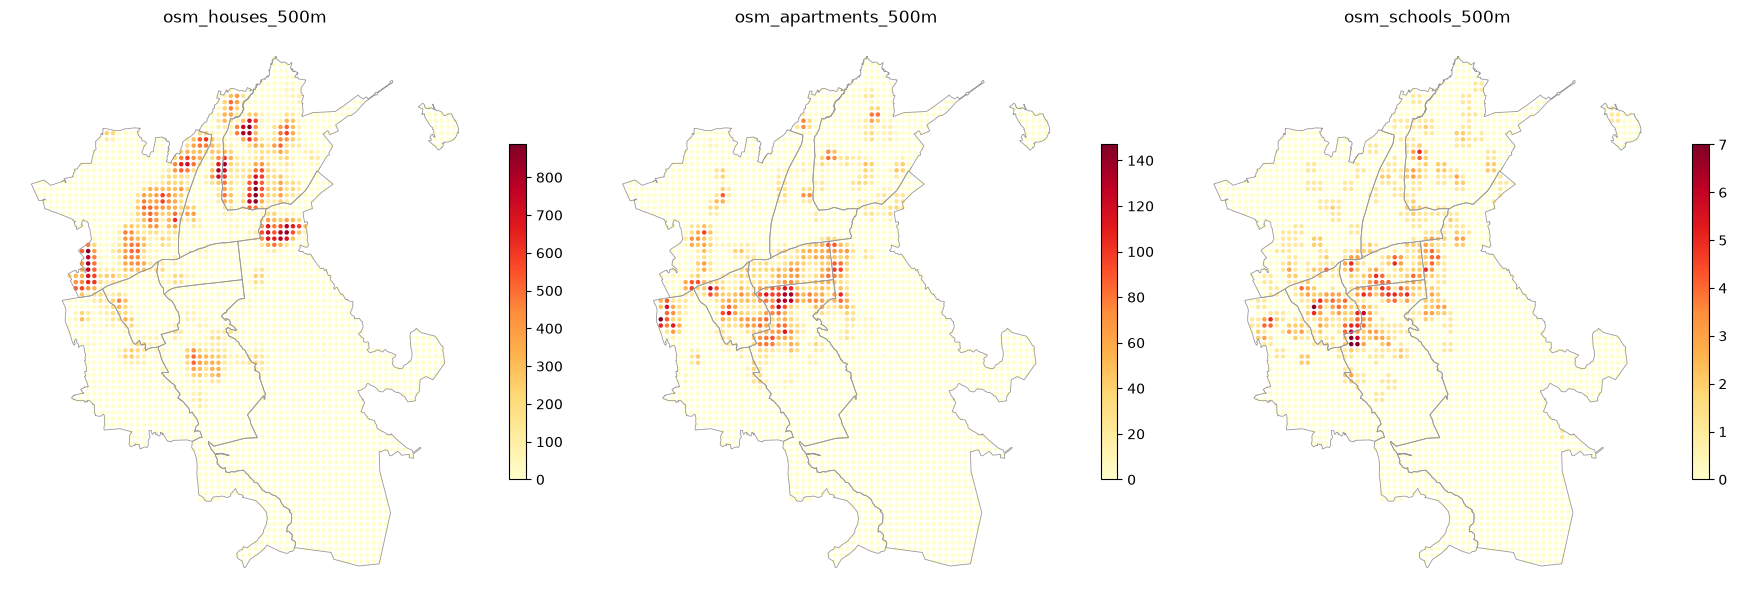

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
plot = candidates.merge(features, on="candidate_id", validate="one_to_one")
for ax, col in zip(axes, [f"osm_houses_{RADIUS_M}m", f"osm_apartments_{RADIUS_M}m", f"osm_schools_{RADIUS_M}m"]):
    districts.to_crs(CRS_METRIC).boundary.plot(ax=ax, color="#999999", linewidth=0.6)
    plot.plot(ax=ax, column=col, cmap="YlOrRd", markersize=5, legend=True, legend_kwds={"shrink": 0.5})
    ax.set_title(col)
    ax.set_axis_off()
plt.tight_layout()
plt.show()